--- Training VGG11Custom ---

--- Training ResNet50 ---


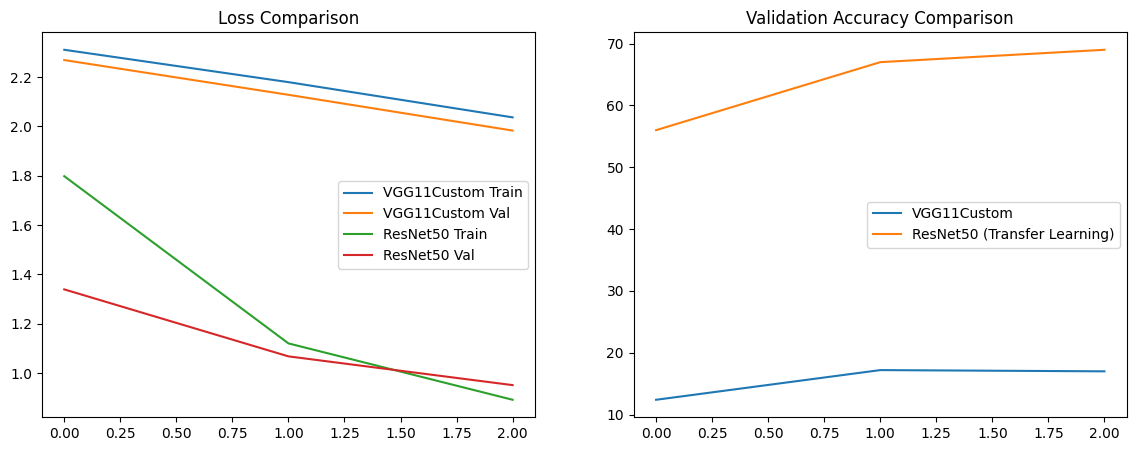

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet50, ResNet50_Weights
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform_vgg = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

transform_transfer = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_data_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_vgg)
test_data_full = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_vgg)

train_dataset_vgg = torch.utils.data.Subset(train_data_full, range(2000))
test_dataset_vgg = torch.utils.data.Subset(test_data_full, range(500))

train_loader_vgg = torch.utils.data.DataLoader(train_dataset_vgg, batch_size=64, shuffle=True)
test_loader_vgg = torch.utils.data.DataLoader(test_dataset_vgg, batch_size=64, shuffle=False)

train_data_tl_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_transfer)
test_data_tl_full = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_transfer)

train_dataset_tl = torch.utils.data.Subset(train_data_tl_full, range(2000))
test_dataset_tl = torch.utils.data.Subset(test_data_tl_full, range(500))

train_loader_tl = torch.utils.data.DataLoader(train_dataset_tl, batch_size=64, shuffle=True)
test_loader_tl = torch.utils.data.DataLoader(test_dataset_tl, batch_size=64, shuffle=False)

class VGG11Custom(nn.Module):
    def __init__(self, num_classes=10):
        super(VGG11Custom, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 1 * 1, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

def build_transfer_learning_model():
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, 10)
    return model

def train_and_evaluate(model, train_loader, test_loader, epochs=3, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    all_preds = []
    all_targets = []

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        history['train_loss'].append(train_loss / len(train_loader))

        model.eval()
        val_loss, correct, total = 0, 0, 0
        epoch_preds, epoch_targets = [], []

        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

                if epoch == epochs - 1:
                    epoch_preds.extend(predicted.cpu().numpy())
                    epoch_targets.extend(labels.cpu().numpy())

        history['val_loss'].append(val_loss / len(test_loader))
        history['val_acc'].append(100. * correct / total)

        if epoch == epochs - 1:
            all_preds = epoch_preds
            all_targets = epoch_targets

    return history, all_targets, all_preds

def plot_performance(hist_vgg, hist_tl):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist_vgg['train_loss'], label='VGG11Custom Train')
    axes[0].plot(hist_vgg['val_loss'], label='VGG11Custom Val')
    axes[0].plot(hist_tl['train_loss'], label='ResNet50 Train')
    axes[0].plot(hist_tl['val_loss'], label='ResNet50 Val')
    axes[0].set_title('Loss Comparison')
    axes[0].legend()

    axes[1].plot(hist_vgg['val_acc'], label='VGG11Custom')
    axes[1].plot(hist_tl['val_acc'], label='ResNet50 (Transfer Learning)')
    axes[1].set_title('Validation Accuracy Comparison')
    axes[1].legend()

    plt.show()

if __name__ == "__main__":
    print("--- Training VGG11Custom ---")
    vgg_model = VGG11Custom()
    hist_vgg, targets_vgg, preds_vgg = train_and_evaluate(vgg_model, train_loader_vgg, test_loader_vgg, epochs=3)

    print("\n--- Training ResNet50 ---")
    tl_model = build_transfer_learning_model()
    hist_tl, targets_tl, preds_tl = train_and_evaluate(tl_model, train_loader_tl, test_loader_tl, epochs=3)

    plot_performance(hist_vgg, hist_tl)